# Sugerencia de mejora: Proyecto Macro

*por: Equipo Sociedad*

El trabajo está muy completo y las conclusiones están bien comunicadas. Todo estaba bien subido y documentado en el repositorio de GitHub y pudimos clonarlo sin problemas. Este script propone **una sugerencia menor de consistencia** sobre el período de una de las tendencias.

## 1. Qué observamos

El trabajo declara como período de análisis 2006-2018 para la actividad, sin embargo, la tendencia de actividad de las secciones 5 y 9.9 se calcula con la serie completa del archivo, 2000-2018.

Para pobreza y desempleo esto no cambia nada, porque sus series arrancan en 2006. Pero el archivo de actividad empieza en 2000, así que esa tendencia incluye seis años que no están en el resto del análisis.

Usar la serie completa de cada variable es una decisión válida y está justificada en el código: así la tendencia se puede calcular aunque haya pocos años de datos.

**Dónde se nota:** en el gráfico 9.2, la actividad de Montevideo sube entre 2006 y 2018 (de 1,23 a 1,27). En cambio, en el gráfico 9.9 Montevideo aparece en rojo, con tendencia negativa. Los dos resultados son correctos, pero miden períodos distintos.

## 2. Dos opciones

**Opción 1: Aclarar el período.** Mantener el cálculo como está y agregar el período en el título del gráfico 9.9 y en la nota de la sección 5:

```python
# En la lista "indicadores" de la sección 9.9
("tend_actividad", "Actividad (2000-2018)", "unidades/año", +1)
```

**Opción 2: Recortar a 2006**, si prefieren que todo el trabajo hable del mismo período. Es un cambio de una línea en la sección 5:

```python
"tend_actividad": tendencia_por_depto(actividad[actividad["Año"] >= 2006], "Actividad"),
```

##3. Comparación de las 2 opciones (código con cambios)

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

DATA_DIR = Path("./data")
DATA_DIR.mkdir(exist_ok=True)

FILES = {
    "actividad": DATA_DIR / "actividad.csv",
    "pobreza":   DATA_DIR / "pobreza.csv",
    "desempleo": DATA_DIR / "desempleo.csv",
}

MONTEVIDEO = "Montevideo"
ANIO_INICIO = 2006   # inicio del período que usa el resto del trabajo
ANIO_FIN = 2018      # último año con dato de actividad

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [2]:
# Subida de archivos en Colab (misma lógica que el script original).
# Se reconocen por una palabra clave en el nombre: "actividad", "pobreza", "desempleo".
CLAVES = {"actividad": "actividad", "pobreza": "pobreza", "desempleo": "desempleo"}
try:
    from google.colab import files
    import shutil
    import unicodedata

    def normalizar(nombre):
        sin_tildes = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode()
        return re.sub(r"[^a-z0-9]", "", sin_tildes.lower())

    uploaded = files.upload()  # elegí los archivos en el diálogo
    for rol, clave in CLAVES.items():
        candidatos = [n for n in uploaded if clave in normalizar(n)
                      and Path(n).suffix.lower() == FILES[rol].suffix]
        if candidatos:
            shutil.copy(candidatos[-1], FILES[rol])
            print(f"  {rol:10s} <- {candidatos[-1]}")
        else:
            print(f"  (no se subió el archivo de {rol})")
except ImportError:
    pass  # fuera de Colab: los archivos ya tienen que estar en ./data/

Saving cdd proyecto - actividad 2000-2018.csv to cdd proyecto - actividad 2000-2018.csv
Saving cdd proyecto - desempleo.csv to cdd proyecto - desempleo.csv
Saving cdd proyecto - educacion.csv to cdd proyecto - educacion.csv
Saving cdd proyecto - pobreza.csv to cdd proyecto - pobreza.csv
Saving cdd proyecto - puertos.xlsx to cdd proyecto - puertos.xlsx
Saving cdd proyecto - salarios.csv to cdd proyecto - salarios.csv
  actividad  <- cdd proyecto - actividad 2000-2018.csv
  pobreza    <- cdd proyecto - pobreza.csv
  desempleo  <- cdd proyecto - desempleo.csv


In [3]:
# Funciones copiadas del script original, sin cambios.

def parse_numero_uy(valor):
    if pd.isna(valor):
        return np.nan
    if isinstance(valor, (int, float)):
        return float(valor)
    s = str(valor).strip()
    if s == "" or s.lower() in ("nan", "..", "-"):
        return np.nan
    s = s.replace(".", "").replace(",", ".")
    try:
        return float(s)
    except ValueError:
        return np.nan


def cargar_ancho_a_largo(path, value_name, extra_id_cols=None):
    extra_id_cols = extra_id_cols or []
    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path, sep=";", encoding="utf-8-sig", dtype=str)
    else:
        df = pd.read_excel(path, dtype=str)
    df.columns = [str(c).strip().strip('"') for c in df.columns]
    id_cols = ["Departamento"] + extra_id_cols
    year_cols = [c for c in df.columns if re.fullmatch(r"\d{4}", c)]
    largo = df.melt(id_vars=id_cols, value_vars=year_cols,
                    var_name="Año", value_name=value_name)
    largo["Año"] = largo["Año"].astype(int)
    largo[value_name] = largo[value_name].apply(parse_numero_uy)
    largo["Departamento"] = largo["Departamento"].astype(str).str.strip().str.strip('"')
    largo = largo[largo["Departamento"].str.lower() != "total"]
    return largo.dropna(subset=[value_name])


def pendiente(df, var):
    d = df[["Año", var]].dropna()
    if len(d) < 3:
        return np.nan
    return stats.linregress(d["Año"], d[var]).slope


def tendencia_por_depto(df, var):
    return df.groupby("Departamento")[["Año", var]].apply(lambda g: pendiente(g, var))


def fmt(v, dec=0):
    return f"{v:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

In [4]:
# Primera aclaración de las fechas
actividad = cargar_ancho_a_largo(FILES["actividad"], "Actividad")
pobreza = cargar_ancho_a_largo(FILES["pobreza"], "Pobreza_%")
desempleo = cargar_ancho_a_largo(FILES["desempleo"], "Desempleo_%")

for nombre, df in [("actividad", actividad), ("pobreza", pobreza), ("desempleo", desempleo)]:
    print(f"  {nombre:10s} {df['Departamento'].nunique()} deptos, años {df['Año'].min()}-{df['Año'].max()}")

print(f"\n→ La serie de actividad arranca en {actividad['Año'].min()}, "
      f"pero el resto del análisis usa {ANIO_INICIO}-{ANIO_FIN}.")

  actividad  19 deptos, años 2000-2018
  pobreza    19 deptos, años 2006-2023
  desempleo  19 deptos, años 2006-2024

→ La serie de actividad arranca en 2000, pero el resto del análisis usa 2006-2018.


Tabla de comparación de las dos opciones

In [5]:
act_periodo = actividad[actividad["Año"].between(ANIO_INICIO, ANIO_FIN)]

comparacion = pd.DataFrame({
    f"Opción 1: serie completa ({actividad['Año'].min()}-{actividad['Año'].max()})": tendencia_por_depto(actividad, "Actividad"),
    f"Opción 2: recortada ({ANIO_INICIO}-{ANIO_FIN})": tendencia_por_depto(act_periodo, "Actividad"),
})
col_orig, col_corr = comparacion.columns
comparacion["Cambia de signo"] = np.where(
    np.sign(comparacion[col_orig]) != np.sign(comparacion[col_corr]), "Sí", "")
comparacion = comparacion.sort_values(col_corr, ascending=False)

(comparacion.style
    .format({c: (lambda v: f"{v:+.4f}".replace(".", ",")) for c in (col_orig, col_corr)})
    .set_caption("Tendencia de actividad por departamento (unidades/año)"))

,Opción 1: serie completa (2000-2018),Opción 2: recortada (2006-2018),Cambia de signo
Departamento,,,
Durazno,"+0,0109","+0,0156",
Artigas,"+0,0152","+0,0121",
Lavalleja,"+0,0178","+0,0119",
Rocha,"+0,0135","+0,0068",
Florida,"+0,0122","+0,0067",
Cerro Largo,"+0,0106","+0,0064",
Colonia,"+0,0303","+0,0063",
Montevideo,"-0,0082","+0,0048",Sí
Treinta y Tres,"+0,0131","+0,0047",


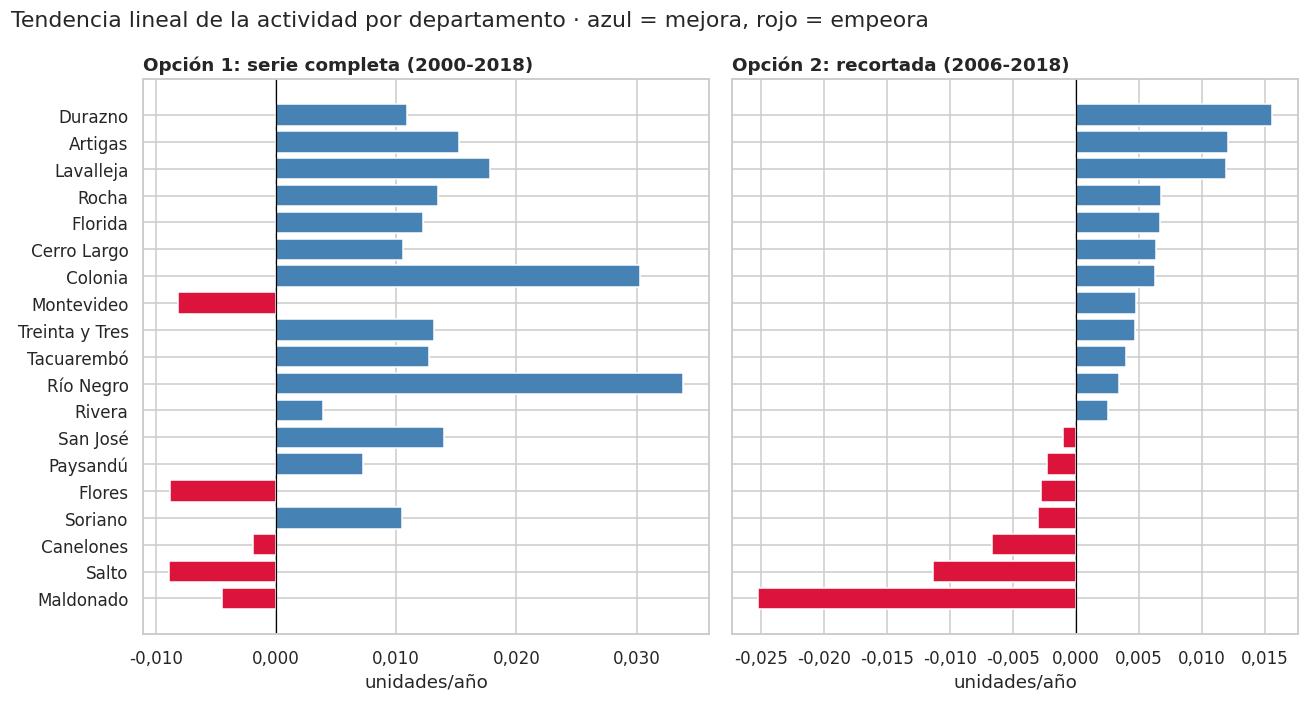

In [6]:
# Mismo estilo que el gráfico 9.9 original: azul = mejora, rojo = empeora
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
orden = comparacion.index[::-1]
for ax, col in zip(axes, [col_orig, col_corr]):
    s = comparacion.loc[orden, col]
    ax.barh(s.index, s.values, color=["steelblue" if v > 0 else "crimson" for v in s])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(col, loc="left", fontweight="bold")
    ax.set_xlabel("unidades/año")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.3f}".replace(".", ",")))
fig.suptitle("Tendencia lineal de la actividad por departamento · azul = mejora, rojo = empeora",
             x=0.01, ha="left")
fig.tight_layout()
plt.show()

Chequeo con el gráfico 9.2 (Montevideo)

In [7]:
mvd = act_periodo[act_periodo["Departamento"] == MONTEVIDEO].set_index("Año")["Actividad"].sort_index()
print(f"Montevideo en el gráfico 9.2: {fmt(mvd.iloc[0], 2)} en {mvd.index[0]} → "
      f"{fmt(mvd.iloc[-1], 2)} en {mvd.index[-1]}")
print(f"Tendencia opción 1 (serie completa): {fmt(comparacion.loc[MONTEVIDEO, col_orig], 4)} por año")
print(f"Tendencia opción 2 (2006-2018):     {fmt(comparacion.loc[MONTEVIDEO, col_corr], 4)} por año")

coincide = np.sign(comparacion.loc[MONTEVIDEO, col_corr]) == np.sign(mvd.iloc[-1] - mvd.iloc[0])
print("\n→ Con la opción 2, la tendencia de Montevideo",
      "coincide" if coincide else "todavía no coincide",
      "con lo que muestra el gráfico 9.2.")

Montevideo en el gráfico 9.2: 1,23 en 2006 → 1,27 en 2018
Tendencia opción 1 (serie completa): -0,0082 por año
Tendencia opción 2 (2006-2018):     0,0048 por año

→ Con la opción 2, la tendencia de Montevideo coincide con lo que muestra el gráfico 9.2.


### Cambio en las conclusiones

Con la opción 1 las conclusiones quedan igual que en el trabajo original, solo con el período aclarado. Con la opción 2 cambian las frases que dependen de esta tendencia: la de las secciones 5 y 9.9 (*"la actividad crece en X de 19 departamentos"*) y la de la relación entre las tendencias de actividad y las de pobreza y desempleo.

In [12]:
tend_pob = tendencia_por_depto(pobreza, "Pobreza_%")
tend_des = tendencia_por_depto(desempleo, "Desempleo_%")

filas = []
for col in [col_orig, col_corr]:
    t = comparacion[col].dropna()
    r_pob = stats.pearsonr(*pd.concat([t, tend_pob], axis=1).dropna().T.values)[0]
    r_des = stats.pearsonr(*pd.concat([t, tend_des], axis=1).dropna().T.values)[0]
    filas.append({
        "Versión": col,
        "Deptos. donde crece la actividad": f"{int((t > 0).sum())} de {len(t)}",
        "Crece más rápido": t.idxmax(),
        "Crece más lento": t.idxmin(),
        "r con tendencia de pobreza": round(r_pob, 2),
        "r con tendencia de desempleo": round(r_des, 2),
    })
cambio = pd.DataFrame(filas).set_index("Versión").T
cambio

Versión,Opción 1: serie completa (2000-2018),Opción 2: recortada (2006-2018)
Deptos. donde crece la actividad,14 de 19,12 de 19
Crece más rápido,Río Negro,Durazno
Crece más lento,Salto,Maldonado
r con tendencia de pobreza,-0.18,-0.57
r con tendencia de desempleo,-0.14,-0.11


In [13]:
# Resumen
cambian = comparacion.index[comparacion["Cambia de signo"] == "Sí"].tolist()
t_o, t_c = comparacion[col_orig], comparacion[col_corr]

print("RESUMEN")
print(f"  • Departamentos que cambian de signo con la opción 2: "
      f"{len(cambian)}" + (f" ({', '.join(cambian)})" if cambian else ""))
print(f"  • La actividad crece en {int((t_o > 0).sum())} de 19 con la serie completa "
      f"y en {int((t_c > 0).sum())} de 19 con {ANIO_INICIO}-{ANIO_FIN}.")
perdieron = [d for d in t_c.index if t_c[d] < 0 and tend_pob.get(d, 0) < 0]
print(f"  • Departamentos que pierden actividad en {ANIO_INICIO}-{ANIO_FIN} aunque baje su pobreza: "
      f" {', '.join(perdieron) if perdieron else 'ninguno'}.")

RESUMEN
  • Departamentos que cambian de signo con la opción 2: 4 (Montevideo, San José, Paysandú, Soriano)
  • La actividad crece en 14 de 19 con la serie completa y en 12 de 19 con 2006-2018.
  • Departamentos que pierden actividad en 2006-2018 aunque baje su pobreza:  San José, Paysandú, Flores, Soriano, Canelones, Salto, Maldonado.
